<a href="https://colab.research.google.com/github/pendulumswings/pendulumswings.github.io/blob/main/scripts/chapter4/pinn_1_hidden_layer_time_break.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1 Hidden Layer PINN to solve the pendulum equation for the first $25$ secs using $5$ secs domain decomposition. Drop angle is $\pi/4=45^{\circ}$.

Starting Sequential PINN Training (Domain Decomposition)...

--- Training Interval 1/5 : t = [0.0, 5.0] ---


/tmp/ipykernel_1497/916260967.py:98: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  res = minimize(


Interval Complete! Final Loss: 0.000450

--- Training Interval 2/5 : t = [5.0, 10.0] ---
Interval Complete! Final Loss: 0.003252

--- Training Interval 3/5 : t = [10.0, 15.0] ---
Interval Complete! Final Loss: 0.073027

--- Training Interval 4/5 : t = [15.0, 20.0] ---
Interval Complete! Final Loss: 0.025770

--- Training Interval 5/5 : t = [20.0, 25.0] ---
Interval Complete! Final Loss: 0.000243


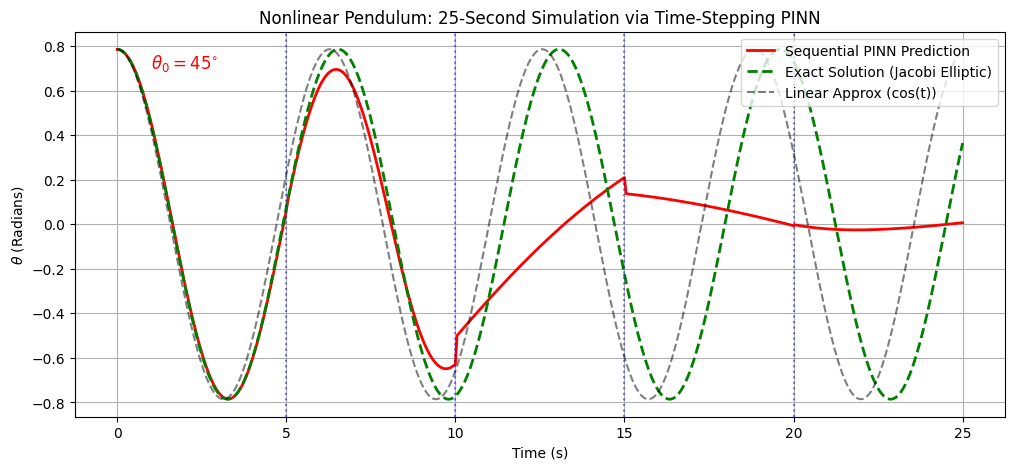

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
import scipy.special as sp

class PureNumpyPINN:
    def __init__(self, n_hidden=32):
        self.H = n_hidden

        # Initialize Weights and Biases
        self.W1 = np.random.randn(1, self.H) * np.sqrt(2.0 / (1 + self.H))
        self.b1 = np.zeros((1, self.H))
        self.W2 = np.random.randn(self.H, 1) * np.sqrt(2.0 / (self.H + 1))
        self.b2 = np.zeros((1, 1))

    def pack_weights(self):
        """Flattens all weights and biases into a single 1D array for SciPy."""
        flat_list = [w.flatten() for w in self.W1]
        flat_list.extend([w.flatten() for w in self.W2])
        flat_list.extend([b.flatten() for b in self.b1])
        flat_list.extend([b.flatten() for b in self.b2])
        return np.concatenate(flat_list)

    def unpack_weights(self, params):
        """Reconstructs the weight matrices from the SciPy 1D array."""
        idx = 0
        self.W1 = params[idx : idx+self.H].reshape(1, self.H); idx += self.H
        self.b1 = params[idx : idx+self.H].reshape(1, self.H); idx += self.H
        self.W2 = params[idx : idx+self.H].reshape(self.H, 1); idx += self.H
        self.b2 = params[idx : idx+1].reshape(1, 1)

    def forward_with_physics(self, t):
        """Calculates the angle, velocity, and acceleration analytically."""
        z = np.dot(t, self.W1) + self.b1
        a = np.tanh(z)
        theta = np.dot(a, self.W2) + self.b2

        # First Derivative (Velocity)
        da_dt = (1 - a**2) * self.W1
        velocity = np.dot(da_dt, self.W2)

        # Second Derivative (Acceleration)
        d2a_dt2 = -2 * a * (1 - a**2) * (self.W1**2)
        acceleration = np.dot(d2a_dt2, self.W2)

        return theta, velocity, acceleration

    def compute_loss(self, params, t_domain, t_ic, theta_0, omega_0):
        """Calculates the total error (Physics + Initial Conditions)."""
        self.unpack_weights(params)

        # 1. Physics Loss: theta'' + sin(theta) = 0
        theta, _, acceleration = self.forward_with_physics(t_domain)
        residual = acceleration + np.sin(theta)
        loss_ode = np.mean(residual**2)

        # 2. Initial Condition Loss
        theta_pred_ic, velocity_pred_ic, _ = self.forward_with_physics(t_ic)
        loss_ic_position = np.mean((theta_pred_ic - theta_0)**2)
        loss_ic_velocity = np.mean((velocity_pred_ic - omega_0)**2)

        return loss_ode + loss_ic_position + loss_ic_velocity

# ==========================================
# Time-Stepping Training Setup
# ==========================================

intervals = 5          # Number of chunks to simulate
chunk_duration = 5.0   # 5 seconds per chunk (Total = 25s)
points_per_chunk = 100

# Lists to store the stitched results
global_t = []
global_theta = []

# Global Initial Conditions at t = 0
theta_0 = np.pi / 4          # Save the true initial angle for the exact solution plot
current_theta_0 = theta_0    # This variable will be updated at each step
current_omega_0 = 0.0

print("Starting Sequential PINN Training (Domain Decomposition)...")

for step in range(intervals):
    t_start = step * chunk_duration
    t_end = (step + 1) * chunk_duration

    print(f"\n--- Training Interval {step + 1}/{intervals} : t = [{t_start}, {t_end}] ---")

    # 1. Define the domain and IC specifically for this chunk
    t_domain = np.linspace(t_start, t_end, points_per_chunk).reshape(-1, 1)
    t_ic = np.array([[t_start]])

    # 2. Initialize a fresh PINN for this interval
    pinn = PureNumpyPINN(n_hidden=32)
    initial_weights = pinn.pack_weights()

    # 3. Train the network for this chunk using SciPy
    res = minimize(
        fun=pinn.compute_loss,
        x0=initial_weights,
        args=(t_domain, t_ic, current_theta_0, current_omega_0),
        method='L-BFGS-B',
        jac='2-point',
        options={'maxiter': 5000, 'disp': False} # Set disp=False to reduce console spam
    )

    pinn.unpack_weights(res.x)
    print(f"Interval Complete! Final Loss: {res.fun:.6f}")

    # 4. Predict the motion over this interval
    theta_pred, vel_pred, _ = pinn.forward_with_physics(t_domain)

    # 5. Extract the LAST point's state to serve as the IC for the NEXT interval
    current_theta_0 = theta_pred[-1, 0]
    current_omega_0 = vel_pred[-1, 0]

    # 6. Store the results (avoiding duplicating the overlapping boundary points)
    if step == 0:
        global_t.append(t_domain)
        global_theta.append(theta_pred)
    else:
        global_t.append(t_domain[1:])
        global_theta.append(theta_pred[1:])

# ==========================================
# Stitch and Plot
# ==========================================

# Concatenate the lists into single arrays
final_t = np.vstack(global_t)
final_theta = np.vstack(global_theta)

plt.figure(figsize=(12, 5))
plt.plot(final_t, final_theta, 'r-', linewidth=2, label='Sequential PINN Prediction')

# Calculate the True Exact Solution (Jacobi Elliptic Functions)
k = np.sin(theta_0 / 2)
m = k**2

# ellipj returns (sn, cn, dn, ph).
sn, cn, dn, ph = sp.ellipj(final_t.flatten(), m)

# To start at maximum amplitude (like a cosine wave), we must use
# the 'cd' function, which is defined as cn / dn
cd = cn / dn

exact_solution = 2 * np.arcsin(k * cd)

# Plot the Exact Solution over the full 25 seconds for comparison
plt.plot(final_t, exact_solution, 'g--', linewidth=2, label='Exact Solution (Jacobi Elliptic)')

# Plot the linear approximation over the full 25 seconds for comparison
linear_solution = (np.pi / 4) * np.cos(final_t)
plt.plot(final_t, linear_solution, 'k--', alpha=0.5, label='Linear Approx (cos(t))')

# Add vertical lines to show where the domains were stitched together
for i in range(1, intervals):
    plt.axvline(x=i * chunk_duration, color='blue', linestyle=':', alpha=0.5)

plt.title("Nonlinear Pendulum: 25-Second Simulation via Time-Stepping PINN")
plt.xlabel("Time (s)")
plt.ylabel("$\\theta$ (Radians)")
plt.text(1, 0.7, "$\\theta_{0}=45^{\\circ}$", fontsize=12, color='red')
plt.legend(loc='upper right')
plt.grid(True)
plt.show()